## <center> ML Assignment 2 </center>
#### <center>BITS ID: 2026AJ05647</center>

### <center><u>Obesity Level Classification</u></center>

### Problem statement
Obesity is one of the major health concerns in recent years, affecting individuals across different age groups and populations. It can increase the risk of several health conditions, including cardiovascular diseases and other disorders. Obesity levels depends on demographic characteristics, eating habits, family history, and physical activity.

Machine learning techniques such as multi-class classification models can be implemented and evaluated using appropriate metrics to classify individuals into one of the seven obesity-level categories by identifying patterns in their demographic characteristics, eating habits, family history, and physical activity.


### Dataset description
<p><b>Dataset:</b> Estimation of Obesity Levels Based on Eating Habits and Physical Condition</p>
<p><b>UCI Machine Learning Repository:</b> <a href="https://archive.ics.uci.edu/dataset/544/estimation+of+obesity+levels+based+on+eating+habits+and+physical+condition">Estimation of Obesity Levels Based on Eating Habits and Physical Condition</a></p>

<p>Total Number of records : 2111</p>
<p>Number of features : 17</p>
<p>Target variable: 'NObeyesdad' (Obesity level)</p>

<p>Features includes demographic/physical characteristics, family history, eating habits, and lifestyle behaviours.</p> 
<p>The target has seven classes: Insufficient Weight, Normal Weight, Overweight Level I, Overweight Level II, Obesity Type I, Obesity Type II, and Obesity Type III.</p>

In [1]:
# libraries to perform dataset manipulation
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import math
import matplotlib.pyplot as plt

# libraries to perform data pre-processing
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# libraries to build classification algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, ConfusionMatrixDisplay, classification_report
)

import joblib

### Load data

In [2]:
df = pd.read_csv("ObesityDataSet_raw_and_data_sinthetic.csv")
print(f"Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2111, 17)


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


### Summary of data

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2111 entries, 0 to 2110
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Gender                          2111 non-null   object 
 1   Age                             2111 non-null   float64
 2   Height                          2111 non-null   float64
 3   Weight                          2111 non-null   float64
 4   family_history_with_overweight  2111 non-null   object 
 5   FAVC                            2111 non-null   object 
 6   FCVC                            2111 non-null   float64
 7   NCP                             2111 non-null   float64
 8   CAEC                            2111 non-null   object 
 9   SMOKE                           2111 non-null   object 
 10  CH2O                            2111 non-null   float64
 11  SCC                             2111 non-null   object 
 12  FAF                             21

<b>Observations:</b> There are no missing values in the data and features are primarily of float and str data types.

### Exploratory Data Analysis

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,2111.0,24.312600,6.345968,14.00,19.947192,22.777890,26.000000,61.00
Height,2111.0,1.701677,0.093305,1.45,1.630000,1.700499,1.768464,1.98
Weight,2111.0,86.586058,26.191172,39.00,65.473343,83.000000,107.430682,173.00
FCVC,2111.0,2.419043,0.533927,1.00,2.000000,2.385502,3.000000,3.00
NCP,2111.0,2.685628,0.778039,1.00,2.658738,3.000000,3.000000,4.00
CH2O,2111.0,2.008011,0.612953,1.00,1.584812,2.000000,2.477420,3.00
FAF,2111.0,1.010298,0.850592,0.00,0.124505,1.000000,1.666678,3.00
TUE,2111.0,0.657866,0.608927,0.00,0.000000,0.625350,1.000000,2.00


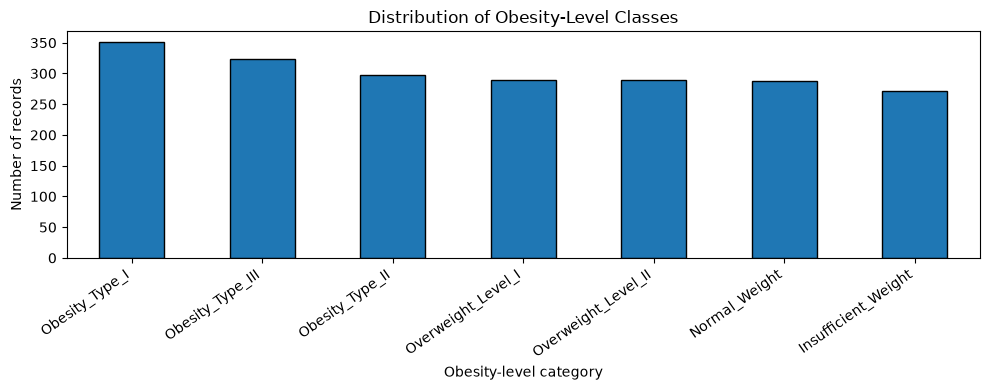

,count,percentage
NObeyesdad,,
Obesity_Type_I,351,16.63
Obesity_Type_III,324,15.35
Obesity_Type_II,297,14.07
Overweight_Level_I,290,13.74
Overweight_Level_II,290,13.74
Normal_Weight,287,13.60
Insufficient_Weight,272,12.88


In [5]:
# Plot the target class distribution to see how many records belong to each class.
target = "NObeyesdad"
class_counts = df[target].value_counts()
ax = class_counts.plot(kind="bar", figsize=(10, 4), edgecolor="black")
ax.set_title("Distribution of Obesity-Level Classes")
ax.set_xlabel("Obesity-level category")
ax.set_ylabel("Number of records")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Display both counts and percentages for each class.
class_summary = class_counts.to_frame("count")
class_summary["percentage"] = (class_summary["count"] / len(df) * 100).round(2)
display(class_summary)


<b>Observations:</b> The records are evenly distributed across all target labels.

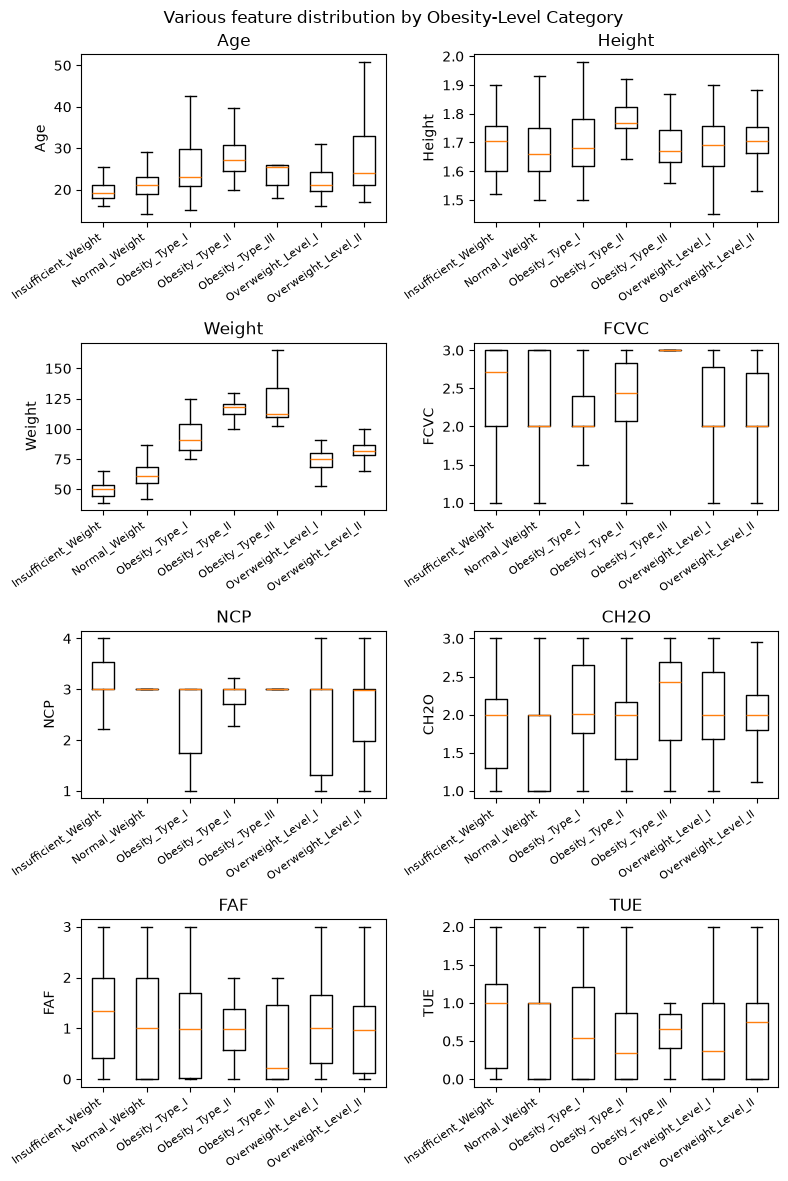

In [6]:
class_order = sorted(df[target].dropna().unique())

# take only numeric features
num_features = [
    col for col in df.select_dtypes(include=[np.number]).columns
    if col != target
]

cols = 2
rows = math.ceil(len(num_features) / cols)

# set the plot area
fig, axes = plt.subplots(
    rows, cols,
    figsize=(4.0 * cols, 3.0 * rows),
    squeeze=False
)
axes = axes.flatten()

# plot for all features
for ax, feature in zip(axes, num_features):
    feature_groups = [
        df.loc[df[target] == label, feature].dropna()
        for label in class_order
    ]

    ax.boxplot(feature_groups, showfliers=False)
    ax.set_title(feature)
    ax.set_xticks(range(1, len(class_order) + 1))
    ax.set_xticklabels(class_order, rotation=35, ha="right", fontsize=8)
    ax.set_ylabel(feature)
    
fig.suptitle("Various feature distribution by Obesity-Level Category")
plt.tight_layout()
plt.show()

### Data Preprocessing

In [7]:
# split target and features
x = df.drop(columns=[target]).copy()
y = df[target].astype(str).copy()

# split categorical and numeric features
categorical_features = x.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
numeric_features = [column for column in x.columns if column not in categorical_features]

# Split the data into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.20, random_state=42, stratify=y
)
print(f"Number of training records: {len(X_train)}")
print(f"Number of test records: {len(X_test)}")


Number of training records: 1688
Number of test records: 423


### Initialize Classification models

In [8]:
# Create a preprocessor for the data.
def make_preprocessor(dense=False):
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=not dense)

    transform_numeric_values = Pipeline([
        ("imputer", SimpleImputer(strategy="median")), # substitute missing values with median for numeric features as its is less sensitive to outliers than mean
        ("scaler", StandardScaler())
    ])
    transform_categorical_values = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")), # substitute missing values with most frequent value (mode) for categorical features
        ("onehot", one_hot_encoder)
    ])
    return ColumnTransformer([
        ("numeric", transform_numeric_values, numeric_features),
        ("categorical", transform_categorical_values, categorical_features)
    ])

# Initialize the models with their respective pipelines
models = {
    "Logistic Regression": Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", LogisticRegression(max_iter=3000, random_state=42))
    ]),
    "Decision Tree": Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", DecisionTreeClassifier(random_state=42))
    ]),
    "K-Nearest Neighbors": Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Naive Bayes-Gaussian": Pipeline([
        ("preprocess", make_preprocessor(dense=True)),
        ("classifier", GaussianNB())
    ]),
    "Support Vector Machine": Pipeline([
        ("preprocess", make_preprocessor()),
        ("classifier", SVC(kernel="rbf", probability=True, random_state=42))
    ])
}
print("Models configured:", list(models.keys()))


Models configured: ['Logistic Regression', 'Decision Tree', 'K-Nearest Neighbors', 'Naive Bayes-Gaussian', 'Support Vector Machine']


Note: Macro averaging calculates a metric for each class and takes the arithmetic mean.
Macro averaging is used to calculate Precision, Recall, F1-score, and AUC to evaluate the model's performance.

### Training and evaluating classification models

In [9]:
# Train and evaluate each model, storing the results in a list of dictionaries.
metrics = []
fitted_models = {}
predictions = {}

for model_name, model in models.items():
    print("Training:", model_name)
    model.fit(X_train, y_train)  # Fit preprocessing and classifier using training data only.
    
    y_pred = model.predict(X_test)
    fitted_models[model_name] = model
    predictions[model_name] = y_pred

    # AUC needs class probabilities; SVC was configured with probability=True.
    try:
        y_proba = model.predict_proba(X_test)
        class_order = model.named_steps["classifier"].classes_
        auc = roc_auc_score(
            y_test, y_proba, labels=class_order,
            multi_class="ovr", average="macro"
        )
    except Exception as error:
        print(f"AUC unavailable for {model_name}: {error}")
        auc = np.nan

    # Calculate evaluation metrics.
    metrics.append({
        "Model Name": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC (macro OvR)": auc,
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred) # Matthews Correlation Coefficient
    })

# Sort by macro F1
metrics_df = pd.DataFrame(metrics).sort_values("F1 (macro)", ascending=False).reset_index(drop=True)
print("\nModel evaluation results:")
display(metrics_df)


Training: Logistic Regression
Training: Decision Tree
Training: K-Nearest Neighbors
Training: Naive Bayes-Gaussian
Training: Support Vector Machine

Model evaluation results:


,Model Name,Accuracy,AUC (macro OvR),Precision (macro),Recall (macro),F1 (macro),MCC
0,Support Vector Machine,0.924350,0.992921,0.925020,0.922009,0.922968,0.911813
1,Decision Tree,0.914894,0.948826,0.915690,0.911831,0.913257,0.900713
2,Logistic Regression,0.874704,0.983363,0.870709,0.872421,0.870828,0.853869
3,K-Nearest Neighbors,0.825059,0.964954,0.823496,0.818700,0.813140,0.798116
4,Naive Bayes-Gaussian,0.508274,0.837216,0.520701,0.500220,0.451143,0.447055


<b>Observations: </b>

<b>Support Vector Machine</b> achieved the best overall performance with an accuracy of 92.43% and F1-score of 92.29% and highest scores across all other evaluation metrics. This shows that SVM is the most effective classifier for this dataset. It also shows great balance between precision and recall scores.

<b>Decision Tree</b> also peformed well, with an accuracy of 91.49% and an F1-score of 91.33%. Its performance is very close to SVM classifier, showing that it is also a effective classifier for this dataset.


<b>Logistic Regression</b> achieved good results, achieving 87.47% accuracy and an F1-score of 87.08%. Overall, it performed well but below SVM and Decision Tree.

<b>K-Nearest Neighbors (KNN)</b> achieved moderate performance, with 82.51% accuracy and an F1-score of 81.31%, showing lower classification effectiveness.

<b>Gaussian Naive Bayes</b> recorded the lowest performance across all metrics when compared to models, with 50.83% accuracy and an F1-score of 45.11%, showing the difficulty in accurately classifying between the obesity-level categories.

<b>Overall Winner:</b> Based on all evaluation metrics, Support Vector Machine is the overall winner for the obesity classification dataset. It achieved highest accuracy, AUC, precision, recall, F1 score and MCC among all five models showing that its able to accurately classify between the obesity-level categories. F1-score of 92.30% shows a strong balance between precision and recall indicating that the model effectively minimizes both false positives and false negatives across the seven obesity categories.

### Export test data

In [10]:
# Keep the original feature columns and append the known test labels.
test_df = X_test.copy()
test_df[target] = y_test.values
test_df.to_csv("test_data.csv", index=False)
print("test_data.csv saved successfully")
display(test_df.head())

test_data.csv saved successfully


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
572,Female,19.084967,1.768435,49.597765,no,yes,3.000000,3.725797,Sometimes,no,1.191401,no,2.000000,1.000000,Sometimes,Public_Transportation,Insufficient_Weight
370,Male,19.000000,1.800000,60.000000,no,yes,2.000000,3.000000,Sometimes,no,1.000000,no,1.000000,1.000000,no,Public_Transportation,Normal_Weight
1002,Male,24.108711,1.700000,80.761409,yes,yes,2.000000,3.000000,Sometimes,no,2.879402,no,0.000000,0.322405,Sometimes,Public_Transportation,Overweight_Level_II
1837,Female,20.941943,1.812963,138.730619,yes,yes,3.000000,3.000000,Sometimes,no,2.641489,no,0.481555,0.735201,Sometimes,Public_Transportation,Obesity_Type_III
1724,Male,33.293166,1.696412,103.250355,yes,yes,2.679664,2.415522,Sometimes,no,1.000000,no,1.987296,0.000000,no,Public_Transportation,Obesity_Type_II


In [11]:
# create a directory to save the fitted models.
model_dir = Path("model")
model_dir.mkdir(exist_ok=True)

for model_name, model in fitted_models.items():
    # save model with user friendly filename.
    filename = model_name.lower().replace(" ", "_").replace("-", "_") + ".joblib"
    joblib.dump(model, model_dir / filename)
    print("Saved:", model_dir / filename)

# Save the score table for use in the assignment report if needed.
# metrics_df.to_csv("model_metrics.csv", index=False)
# print("model_metrics.csv saved successfully")


Saved: model/logistic_regression.joblib
Saved: model/decision_tree.joblib
Saved: model/k_nearest_neighbors.joblib
Saved: model/naive_bayes_gaussian.joblib
Saved: model/support_vector_machine.joblib
